In [77]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import seaborn as sns

In [ ]:
os.getcwd()

In [ ]:
print("Welcome Guys")

In [ ]:
str="Hello NIC Guys"
first=str.split()
print(first)

In [ ]:
x=10
y=20.5
c=x+y
print(c)

In [ ]:
array1 = np.array([1,2,3,4,5])
print("Numpy array:",array1)

In [ ]:
cubearray= array1 ** 3
print("Cube array:",cubearray)

In [ ]:
years = [2015,2016,2017,2018,2019,2020]
values = [5,6,7,8,9,10]

plt.plot(years,values, marker="x")
plt.title("My Plot X=Year Y=Age")
plt.xlabel("Year")
plt.ylabel("Age")
plt.show()

In [ ]:
data = {
    'Artist': ['Yesudas', 'K S Chitra', 'Sujatha', 'S Janaki', 'Sreya Ghosal'],
    'Years_Active': [50,35,30,40,20],
     'Number_of_Songs': [1000, 700, 600, 1500, 500],
    'Awards_Won': [150, 60, 40, 100, 80]
}

# Convert the dictionary into a Pandas DataFrame
singers_df = pd.DataFrame(data)

# Display the dataset
singers_df

In [ ]:
#to get details of the dataframe
singers_df.info()

In [ ]:
#to get a few details (last,first 3) of the dataframe
singers_df.tail(3)
singers_df.head(3)

In [ ]:
# to get statistical data of a dataframe
singers_df.describe()

In [ ]:
#to get dataframe sorted
sorted_singers = singers_df.sort_values(by='Awards_Won', ascending=False)
sorted_singers

In [ ]:
#to filter the dataframe
singers_with_many_awards = singers_df[singers_df['Awards_Won'] > 50]
singers_with_many_awards

In [ ]:
# Bar chart of the number of songs by each singer
plt.figure(figsize=(8, 5))
plt.bar(singers_df['Artist'], singers_df['Number_of_Songs'], color='lightblue')
plt.title('Number of Songs by Indian Singers')
plt.xlabel('Singer')
plt.ylabel('Number of Songs')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [ ]:
#read data from csv
df= pd.read_csv('Assgn3Data.csv')
df = df.rename(columns={"Target_Value": "Temperature", "f_01": "time", "f_02": "humidity", "f_03": "sunlight", "f_04": "areatype"})
df
# Option B: Direct assignment
#df.columns = ["time", "humidity", "sunlight", "areatype", "Temperature"]

In [ ]:
#prepare your own data set by random
np.random.seed(42)
n_samples = 100
normal_data = {
    'Amount_INR': np.random.randint(150,15000, size=85),
    'Hour_of_Day' : np.random.randint(8,23,size=85),
    'V1_Device_Risk' : np.random.normal(-0.5,0.8,size=85).round(2),
    'V2_Velocity_Score' : np.random.normal(-0.4,0.7,size=85).round(2),
    'Is_International' : np.random.choice([0,1],size=85, p=[0.95,0.05]),
    'Class': np.zeros(85,dtype=int)
}

fraud_data = {
    'Amount_INR': np.random.randint(25000,95000, size=15),
    'Hour_of_Day' : np.random.choice([1,2,3,4,23],size=15),
    'V1_Device_Risk' : np.random.normal(2.2,0.9,size=15).round(2),
    'V2_Velocity_Score' : np.random.normal(1.9,0.8,size=15).round(2),
    'Is_International' : np.random.choice([0,1],size=15, p=[0.40,0.60]),
    'Class': np.ones(15,dtype=int)
}

df= pd.concat([pd.DataFrame(normal_data),pd.DataFrame(fraud_data)], ignore_index=True )
df=df.sample(frac=1, random_state=42).reset_index(drop=True)

df.head(10)


In [63]:
from sklearn.model_selection import train_test_split

In [65]:
# Introduce 2 realistic "messy" missing values in Amount_INR and clean them
df.loc[4, 'Amount_INR'] = np.nan
df['Amount_INR'] = df['Amount_INR'].fillna(df['Amount_INR'].median())

df.head()

,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Class
0,3223.0,12,1.53,-0.02,0,0
1,8988.0,15,-0.51,0.21,0,0
2,5636.0,14,0.02,-1.45,0,0
3,4808.0,8,-0.85,0.10,0,0
4,8583.0,15,-0.42,-0.76,0,0


In [66]:
# Check how many Normal (0) vs Fraud (1) transactions exist
counts = df['Class'].value_counts()
print("Transaction Breakdown:")
print(f"0 (Genuine): {counts[0]} transactions ({counts[0]}%)")
print(f"1 (Fraud)  : {counts[1]} transactions ({counts[1]}%)")

Transaction Breakdown:
0 (Genuine): 85 transactions (85%)
1 (Fraud)  : 15 transactions (15%)


In [67]:
from sklearn.model_selection import train_test_split

# X = Features (The clues), y = Label (The answer)
X = df.drop(columns=['Class'])
y = df['Class']

# Split: 80% Training Data, 20% Testing Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Total Rows: {len(df)}")
print(f"Training Set (Study Material): {X_train.shape[0]} rows")
print(f"Testing Set  (Unseen Exam)   : {X_test.shape[0]} rows")


Total Rows: 100
Training Set (Study Material): 80 rows
Testing Set  (Unseen Exam)   : 20 rows


In [75]:
X_train.head(20)
y_train.head(20)
X_test.head(20)
y_test.head(20)

22    0
15    0
93    0
92    1
1     0
23    0
33    0
98    1
84    0
72    0
58    0
89    1
42    0
25    0
67    0
68    0
57    0
2     0
82    0
85    0
Name: Class, dtype: int64

In [68]:
from sklearn.linear_model import LogisticRegression

# 1. Initialize and Train the Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("🎯 Model Training Complete!")

# 2. Predict on the unseen 20% test data
predictions = model.predict(X_test)

# 3. Create a clean table of the first 10 test cases WITHOUT actual answers
demo_df = X_test.iloc[:10].copy().reset_index(drop=True)
demo_df['Model_Prediction'] = predictions[:10]

print("\n--- FIRST 10 UNSEEN TEST TRANSACTIONS (ACTUAL LABEL HIDDEN) ---")
demo_df

🎯 Model Training Complete!

--- FIRST 10 UNSEEN TEST TRANSACTIONS (ACTUAL LABEL HIDDEN) ---


,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Model_Prediction
0,6570.0,9,-0.71,-0.57,0,0
1,5341.0,13,2.20,-1.01,0,0
2,7705.0,10,0.59,-0.31,0,0
3,85692.0,1,1.65,2.39,0,1
4,8988.0,15,-0.51,0.21,0,0
5,339.0,14,-1.36,-0.64,0,0
6,4705.0,12,0.52,-0.02,0,0
7,42955.0,1,1.12,2.82,1,1
8,1010.0,13,0.14,-1.41,0,0
9,10777.0,12,-1.14,-0.82,0,0


In [69]:
# Reveal the ground truth alongside the model's prediction
reveal_df = demo_df[['Amount_INR', 'Hour_of_Day', 'Is_International', 'Model_Prediction']].copy()
reveal_df['Actual_Label'] = y_test.iloc[:10].values

# Helper column to label each outcome clearly
def classify_result(row):
    if row['Actual_Label'] == 1 and row['Model_Prediction'] == 1:
        return "✅ True Positive (Caught Fraud!)"
    elif row['Actual_Label'] == 0 and row['Model_Prediction'] == 0:
        return "✅ True Negative (Cleared Genuine)"
    elif row['Actual_Label'] == 0 and row['Model_Prediction'] == 1:
        return "⚠️ False Positive (False Alarm - Blocked Genuine Citizen)"
    else:
        return "🚨 False Negative (Missed Fraud!)"

reveal_df['Outcome_Type'] = reveal_df.apply(classify_result, axis=1)
reveal_df

,Amount_INR,Hour_of_Day,Is_International,Model_Prediction,Actual_Label,Outcome_Type
0,6570.0,9,0,0,0,✅ True Negative (Cleared Genuine)
1,5341.0,13,0,0,0,✅ True Negative (Cleared Genuine)
2,7705.0,10,0,0,0,✅ True Negative (Cleared Genuine)
3,85692.0,1,0,1,1,✅ True Positive (Caught Fraud!)
4,8988.0,15,0,0,0,✅ True Negative (Cleared Genuine)
5,339.0,14,0,0,0,✅ True Negative (Cleared Genuine)
6,4705.0,12,0,0,0,✅ True Negative (Cleared Genuine)
7,42955.0,1,1,1,1,✅ True Positive (Caught Fraud!)
8,1010.0,13,0,0,0,✅ True Negative (Cleared Genuine)
9,10777.0,12,0,0,0,✅ True Negative (Cleared Genuine)


<Axes: >

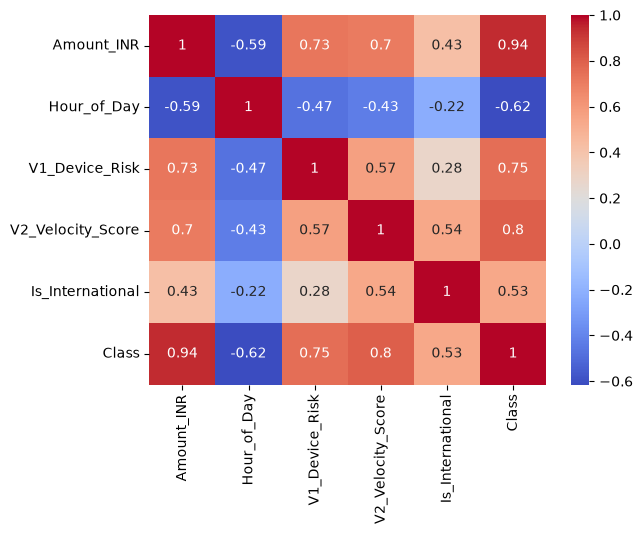

In [78]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')


In [1]:
#tosave dataframe to csv
#df.to_csv('filename.csv', index=False)